Architecture :
- **Orchestrateur** : analyse la demande (catégorie unique), sélectionne l'agent, termine dès qu'une réponse finale est disponible
- **agent_documentaire** : outil distant `rag_multimodal` (serveur MCP, client MCP)
- **agent_garantie** : outil local `consulter_garantie` (registre en lecture seule)

Prérequis : lancer le serveur MCP dans un terminal séparé : `uv run mcp_server.py` (port 23000).

### 1- Imports et configuration

In [9]:
from typing import Annotated, Literal
from typing_extensions import TypedDict
import os
import json
from datetime import date
from pathlib import Path

from IPython.display import Image, Markdown
from dotenv.ipython import load_dotenv

from langgraph.graph import StateGraph, START, END
from langgraph.graph.message import add_messages

from langchain.agents import create_agent
from langchain.tools import tool
from langchain.messages import HumanMessage, AIMessage, SystemMessage
from langchain_google_genai import ChatGoogleGenerativeAI
from langchain_mcp_adapters.client import MultiServerMCPClient

In [10]:
load_dotenv(override=True)

True

In [11]:
# Modèles Gemini (modifiables dans .env : GEMINI_MODEL, GEMINI_ROUTER_MODEL)
# En cas d'erreur 503 (surcharge), changez de modèle, ex: gemini-3.6-flash
GEMINI_MODEL = os.getenv("GEMINI_MODEL", "gemini-3.7-flash")
GEMINI_ROUTER_MODEL = os.getenv("GEMINI_ROUTER_MODEL", "gemini-3.5-flash-lite")

llm = ChatGoogleGenerativeAI(model=GEMINI_MODEL, temperature=0, timeout=60, max_retries=3)

def texte(message) -> str:
    """Retourne le texte d'un message (content peut être une chaîne ou une liste de blocs)."""
    c = message.content
    if isinstance(c, str):
        return c
    return "".join(b.get("text", "") for b in c if isinstance(b, dict))

### 2- Données de test (registre de garantie)

In [12]:
Path("data").mkdir(exist_ok=True)
REGISTRE = Path("data/registre_garanties.json")

if not REGISTRE.exists():
    REGISTRE.write_text(json.dumps({
        "PX200-0042": {"produit": "Imprimante PX-200", "date_achat": "2025-03-15", "duree_mois": 24},
        "PX200-0007": {"produit": "Imprimante PX-200", "date_achat": "2023-01-10", "duree_mois": 24}
    }, indent=2), encoding="utf-8")
print(REGISTRE.read_text(encoding="utf-8"))

{
  "PX200-0042": {
    "produit": "Imprimante PX-200",
    "date_achat": "2025-03-15",
    "duree_mois": 24
  },
  "PX200-0007": {
    "produit": "Imprimante PX-200",
    "date_achat": "2023-01-10",
    "duree_mois": 24
  }
}


### 3- Client MCP : récupérer l'outil distant `rag_multimodal`

In [13]:
mcp_client = MultiServerMCPClient(
    {
        "sav_mcp_server": {
            "transport": "streamable_http",
            "url": "http://127.0.0.1:23000/mcp",
        }
    }
)
mcp_tools = await mcp_client.get_tools()
print([t.name for t in mcp_tools])

['rag_multimodal']


### 4- Outil local `consulter_garantie` (lecture seule)

In [14]:
@tool
def consulter_garantie(numero_serie: str) -> dict:
    """
    Consulte le registre de garantie (lecture seule) à partir d'un numéro de série.
    Args:
        numero_serie: numéro de série de l'appareil (ex: PX200-0042)
    Returns:
        dict avec produit, date d'achat, date de fin de garantie et statut
    """
    print(f"\nconsulter_garantie invoked for {numero_serie}")
    with open(REGISTRE, "r", encoding="utf-8") as f:   # mode lecture seule
        registre = json.load(f)
    fiche = registre.get(numero_serie.strip().upper())
    if not fiche:
        return {"numero_serie": numero_serie, "statut": "introuvable"}
    achat = date.fromisoformat(fiche["date_achat"])
    total_mois = achat.month - 1 + fiche["duree_mois"]
    fin = achat.replace(year=achat.year + total_mois // 12, month=total_mois % 12 + 1)
    return {
        "numero_serie": numero_serie,
        "produit": fiche["produit"],
        "date_achat": fiche["date_achat"],
        "date_fin_garantie": fin.isoformat(),
        "statut": "sous garantie" if date.today() <= fin else "garantie expirée",
    }

In [15]:
print(consulter_garantie.invoke({"numero_serie": "PX200-0042"}))


consulter_garantie invoked for PX200-0042
{'numero_serie': 'PX200-0042', 'produit': 'Imprimante PX-200', 'date_achat': '2025-03-15', 'date_fin_garantie': '2027-03-15', 'statut': 'sous garantie'}


### 5- Agents spécialisés

In [16]:
agent_documentaire = create_agent(
    model=llm,
    tools=mcp_tools,
    system_prompt="""Vous êtes l'agent documentaire du service après-vente.
Pour toute question de dépannage, appelez l'outil rag_multimodal.
Si une photo est jointe, transmettez sa référence dans le paramètre image_ref.
Répondez en français en reprenant les sources fournies par l'outil.""",
)

agent_garantie = create_agent(
    model=llm,
    tools=[consulter_garantie],
    system_prompt="""Vous êtes l'agent garantie du service après-vente.
Extrayez le numéro de série de la demande, appelez l'outil consulter_garantie,
puis indiquez clairement si l'appareil est sous garantie et jusqu'à quelle date.""",
)

### 6- État partagé du graphe

In [17]:
class SAVState(TypedDict, total=False):
    messages: Annotated[list, add_messages]
    image_ref: str
    categorie: Literal["documentation", "garantie"]
    next: Literal["agent_documentaire", "agent_garantie", "FINISH"]
    reponse_finale: str

### 7- Orchestrateur (sortie structurée, une seule catégorie)

In [18]:
# Sortie attendue de l'orchestrateur
class Decision(TypedDict):
    categorie: Literal["documentation", "garantie"]

router_llm = ChatGoogleGenerativeAI(
    model=GEMINI_ROUTER_MODEL, temperature=0, timeout=60, max_retries=3
).with_structured_output(Decision)

def orchestrateur_node(state: SAVState):
    # Réponse finale disponible : l'orchestrateur termine l'exécution
    if state.get("reponse_finale"):
        print("[orchestrateur] réponse finale disponible -> FINISH")
        return {"next": "FINISH"}

    decision = router_llm.invoke([
        SystemMessage(content=(
            "Tu es l'orchestrateur du service après-vente d'un distributeur d'appareils électroniques.\n"
            "Classe la demande dans UNE seule catégorie :\n"
            "- documentation : dépannage, voyant, pictogramme, message d'erreur, utilisation de l'appareil\n"
            "- garantie : vérification de la garantie à partir d'un numéro de série\n"
            "Réponds uniquement avec le champ structuré attendu."
        )),
        *state["messages"]
    ])
    categorie = decision["categorie"]
    print(f"[orchestrateur] catégorie = {categorie}")
    return {
        "categorie": categorie,
        "next": "agent_documentaire" if categorie == "documentation" else "agent_garantie",
    }

def route_after_orchestrateur(state: SAVState):
    return state["next"]

### 8- Nœuds des agents (asynchrones : les outils MCP sont asynchrones)

In [19]:
def derniere_question(state: SAVState) -> str:
    return [m for m in state["messages"] if m.type == "human"][-1].content

async def agent_documentaire_node(state: SAVState):
    consigne = derniere_question(state)
    if state.get("image_ref"):
        consigne += f"\n\n[Photo jointe : image_ref = {state['image_ref']}]"
    result = await agent_documentaire.ainvoke({"messages": [HumanMessage(consigne)]})
    reponse = texte(result["messages"][-1])
    return {
        "messages": [AIMessage(content=reponse, name="agent_documentaire")],
        "reponse_finale": reponse,
    }

async def agent_garantie_node(state: SAVState):
    result = await agent_garantie.ainvoke({"messages": [HumanMessage(derniere_question(state))]})
    reponse = texte(result["messages"][-1])
    return {
        "messages": [AIMessage(content=reponse, name="agent_garantie")],
        "reponse_finale": reponse,
    }

### 9- Construction du graphe

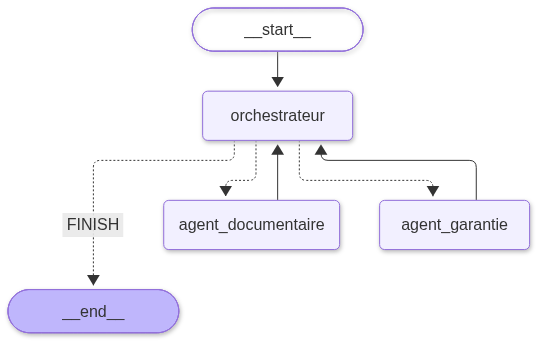

In [20]:
builder = StateGraph(SAVState)

builder.add_node("orchestrateur", orchestrateur_node)
builder.add_node("agent_documentaire", agent_documentaire_node)
builder.add_node("agent_garantie", agent_garantie_node)

builder.add_edge(START, "orchestrateur")
builder.add_conditional_edges(
    "orchestrateur",
    route_after_orchestrateur,
    {
        "agent_documentaire": "agent_documentaire",
        "agent_garantie": "agent_garantie",
        "FINISH": END,
    },
)
# Après traitement, l'agent rend la main à l'orchestrateur
builder.add_edge("agent_documentaire", "orchestrateur")
builder.add_edge("agent_garantie", "orchestrateur")

graph = builder.compile()
display(Image(graph.get_graph().draw_mermaid_png()))

### 10- Exemple 1 : assistance documentaire (catégorie attendue : documentation)

In [21]:
resp1 = await graph.ainvoke({
    "messages": [HumanMessage(
        "Mon imprimante PX-200 affiche un voyant clignotant. "
        "Que signifie le pictogramme sur la photo jointe ?"
    )],
    "image_ref": "img_px200_01",
})

c:\Users\PC\Desktop\AS AI Agents\.venv\Lib\site-packages\langchain_google_genai\chat_models.py:3982: UserWarning: Model 'gemini-3.5-flash-lite' uses fixed sampling defaults; the sampling parameter(s) temperature will be ignored.
  request = self._build_request_config(


[orchestrateur] catégorie = documentation
[orchestrateur] réponse finale disponible -> FINISH


In [22]:
print("Catégorie :", resp1["categorie"], "| Agent :", resp1["messages"][-1].name)
display(Markdown(resp1["reponse_finale"]))

Catégorie : documentation | Agent : agent_documentaire


Le pictogramme représentant une feuille de papier avec un point d'exclamation, associé au voyant orange clignotant, signifie qu'**un bourrage papier a été détecté** (une feuille est coincée dans l'appareil) [P1]. L'impression est suspendue tant que le papier bloqué n'a pas été retiré [P3].

---
**Sources :**
* `manuel_PX200.pdf`, page 1 [P1]
* `manuel_PX200.pdf`, page 3 [P3]

### 11- Exemple 2 : vérification de garantie (catégorie attendue : garantie)

In [23]:
resp2 = await graph.ainvoke({
    "messages": [HumanMessage(
        "Est-ce que mon imprimante est encore sous garantie ? Son numéro de série est PX200-0042."
    )]
})

[orchestrateur] catégorie = garantie

consulter_garantie invoked for PX200-0042
[orchestrateur] réponse finale disponible -> FINISH


In [24]:
print("Catégorie :", resp2["categorie"], "| Agent :", resp2["messages"][-1].name)
display(Markdown(resp2["reponse_finale"]))

Catégorie : garantie | Agent : agent_garantie


Votre imprimante (numéro de série : PX200-0042) est actuellement **sous garantie**. 

La garantie est valable jusqu'au **15 mars 2027**.

### 12- Vérifications

In [25]:
assert resp1["categorie"] == "documentation" and resp1["messages"][-1].name == "agent_documentaire"
assert resp2["categorie"] == "garantie" and resp2["messages"][-1].name == "agent_garantie"
assert resp1["next"] == "FINISH" and resp2["next"] == "FINISH"
print("Tests OK : routage, agents et fin d'exécution conformes")

Tests OK : routage, agents et fin d'exécution conformes


### 13- Suivi pas à pas (streaming)

In [26]:
async for item in graph.astream(
    {"messages": [HumanMessage("Est-ce que ma PX-200 de numéro de série PX200-0007 est sous garantie ?")]},
    stream_mode="values",
):
    item["messages"][-1].pretty_print()

================================ Human Message =================================

Est-ce que ma PX-200 de numéro de série PX200-0007 est sous garantie ?
[orchestrateur] catégorie = garantie
================================ Human Message =================================

Est-ce que ma PX-200 de numéro de série PX200-0007 est sous garantie ?

consulter_garantie invoked for PX200-0007
================================== Ai Message ==================================
Name: agent_garantie

L'appareil associé au numéro de série **PX200-0007** (Imprimante PX-200, acheté le 10/01/2023) **n'est plus sous garantie**. 

Sa période de garantie a pris fin le **10 janvier 2025**.
[orchestrateur] réponse finale disponible -> FINISH
================================== Ai Message ==================================
Name: agent_garantie

L'appareil associé au numéro de série **PX200-0007** (Imprimante PX-200, acheté le 10/01/2023) **n'est plus sous garantie**. 

Sa période de garantie a pris fin le **10 ja